In [2]:
!pip install hmmlearn

import os
import librosa
import numpy as np
import pandas as pd
import scipy.stats
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import warnings
from hmmlearn import hmm

warnings.filterwarnings("ignore")

# Define the pentatonic vocabulary of Raag Bhoopali
bhoopali_allowed = ['S', 'R', 'G', 'P', 'D']

def get_swara_sequence(audio_path):
    """
    Extracts fundamental frequency (f0) using pYIN, detects tonic Sa,
    maps to Bhoopali swaras, and compresses repeated frames.
    """
    try:
        y, sr = librosa.load(audio_path, sr=22050)
        f0, _, _ = librosa.pyin(
            y,
            fmin=librosa.note_to_hz('C2'),
            fmax=librosa.note_to_hz('C5')
        )
        valid_f0 = f0[~np.isnan(f0)]

        if len(valid_f0) == 0:
            return []

        # Find Tonic Sa using the statistical mode of rounded frequencies
        tonic_sa = float(scipy.stats.mode(np.round(valid_f0), keepdims=True).mode[0])
        swaras = librosa.hz_to_svara_h(valid_f0, Sa=tonic_sa)

        # Retain only Bhoopali allowed notes (uppercase base note)
        clean = []
        for s in swaras:
            if len(s) > 0:
                base_swara = s[0].upper()
                if base_swara in bhoopali_allowed:
                    clean.append(base_swara)

        # Compress consecutive duplicate frames into macro-transitions
        compressed = []
        if clean:
            compressed.append(clean[0])
            for i in range(1, len(clean)):
                if clean[i] != clean[i - 1]:
                    compressed.append(clean[i])

        return compressed

    except Exception as e:
        print(f"Skipping {audio_path} due to error: {e}")
        return []

Compressed Sequence (129 notes): ['R', 'S', 'R', 'S', 'R', 'S', 'R', 'S', 'G', 'S', 'R', 'P', 'R', 'P', 'R', 'S', 'R', 'G', 'R', 'S', 'G', 'R', 'G', 'S', 'G', 'D', 'S', 'D', 'S', 'D', 'S', 'D', 'S', 'G', 'P', 'R', 'P', 'G', 'S', 'D', 'S', 'D', 'S', 'R', 'S', 'G', 'S', 'R', 'S', 'P', 'S', 'R', 'G', 'R', 'G', 'S', 'R', 'G', 'R', 'S', 'G', 'S', 'G', 'S', 'G', 'P', 'S', 'D', 'S', 'R', 'G', 'R', 'S', 'D', 'S', 'R', 'S', 'R', 'S', 'P', 'G', 'S', 'D', 'P', 'R', 'S', 'D', 'S', 'R', 'G', 'R', 'G', 'R', 'G', 'R', 'S', 'P', 'D', 'P', 'R', 'S', 'G', 'R', 'S', 'R', 'S', 'R', 'P', 'G', 'P', 'R', 'G', 'R', 'S', 'G', 'R', 'G', 'R', 'S', 'P', 'R', 'G', 'R', 'S', 'R', 'G', 'S', 'D', 'S']


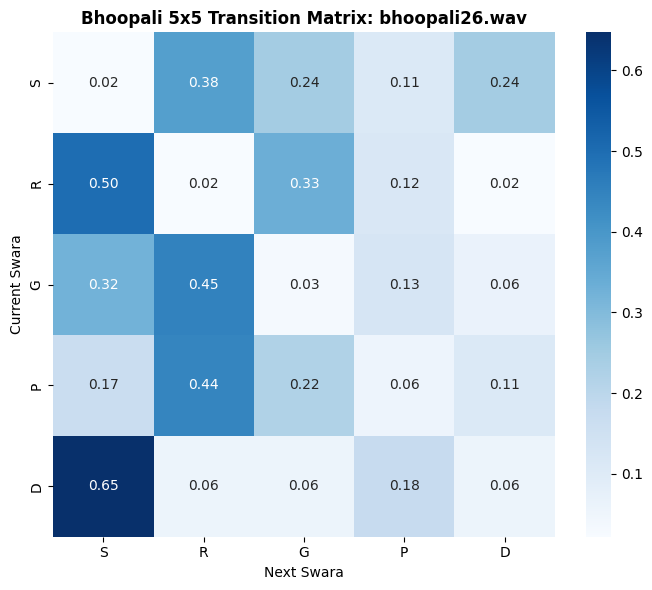

In [3]:
import os
import librosa
import numpy as np
import pandas as pd
import scipy.stats
import matplotlib.pyplot as plt
import seaborn as sns

# File and pentatonic vocabulary configuration
audio_file = 'bhoopali26.wav'
bhoopali_swaras = ['S', 'R', 'G', 'P', 'D']

# 1. Load audio and extract pitch tracks
y, sr = librosa.load(audio_file, sr=22050)
f0, _, _ = librosa.pyin(y, fmin=librosa.note_to_hz('C2'), fmax=librosa.note_to_hz('C5'))
valid_f0 = f0[~np.isnan(f0)]

if len(valid_f0) == 0:
    raise ValueError(f"No clear pitch detected in {audio_file}")

# 2. Tonic detection and swara extraction
tonic_sa = float(scipy.stats.mode(np.round(valid_f0), keepdims=True).mode[0])
raw_swaras = librosa.hz_to_svara_h(valid_f0, Sa=tonic_sa)

# Retain only valid Bhoopali swaras and compress consecutive frame duplicates
clean = [s[0].upper() for s in raw_swaras if len(s) > 0 and s[0].upper() in bhoopali_swaras]
compressed_seq = []
if clean:
    compressed_seq.append(clean[0])
    for idx in range(1, len(clean)):
        if clean[idx] != clean[idx - 1]:
            compressed_seq.append(clean[idx])

print(f"Compressed Sequence ({len(compressed_seq)} notes):", compressed_seq)

# 3. Build 5x5 Transition Matrix strictly for valid notes
counts_df = pd.DataFrame(0, index=bhoopali_swaras, columns=bhoopali_swaras)
for idx in range(len(compressed_seq) - 1):
    curr_n = compressed_seq[idx]
    next_n = compressed_seq[idx + 1]
    if curr_n in counts_df.index and next_n in counts_df.columns:
        counts_df.loc[curr_n, next_n] += 1

# Apply Laplace smoothing (+1) across the 5 valid states
smoothed_counts = counts_df + 1
transition_matrix_5x5 = smoothed_counts.div(smoothed_counts.sum(axis=1), axis=0)

# 4. Plot the 5x5 Heatmap
plt.figure(figsize=(7, 6))
sns.heatmap(
    transition_matrix_5x5,
    annot=True,
    cmap="Blues",
    fmt=".2f",
    cbar=True,
    xticklabels=bhoopali_swaras,
    yticklabels=bhoopali_swaras
)
plt.title(f"Bhoopali 5x5 Transition Matrix: {audio_file}", fontsize=12, fontweight='bold')
plt.xlabel("Next Swara", fontsize=10)
plt.ylabel("Current Swara", fontsize=10)
plt.tight_layout()
plt.show()

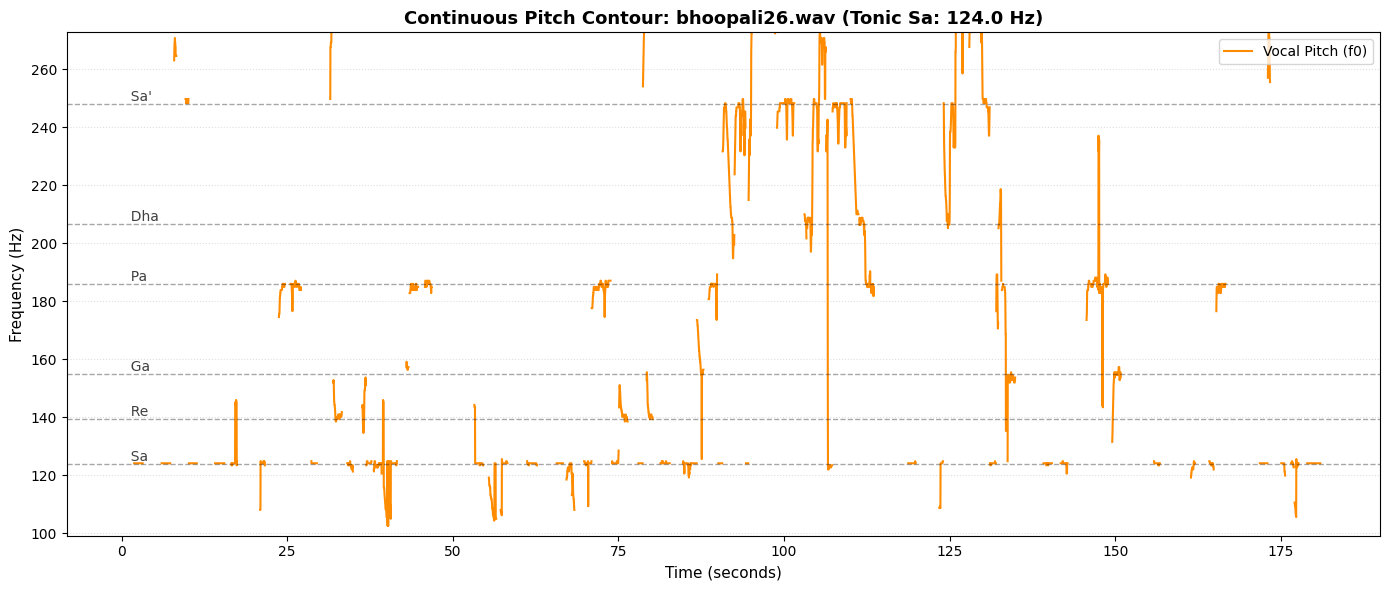

In [4]:
import librosa
import numpy as np
import scipy.stats
import matplotlib.pyplot as plt

# File configuration
audio_file = 'bhoopali26.wav'

# 1. Load audio and extract pitch track
y, sr = librosa.load(audio_file, sr=22050)
f0, _, _ = librosa.pyin(y, fmin=librosa.note_to_hz('C2'), fmax=librosa.note_to_hz('C5'))
times = librosa.times_like(f0)
valid_f0 = f0[~np.isnan(f0)]

if len(valid_f0) == 0:
    raise ValueError(f"No clear pitch detected in {audio_file}")

# 2. Establish Performer's Tonic Sa
tonic_sa = float(scipy.stats.mode(np.round(valid_f0), keepdims=True).mode[0])

# 3. Plot Continuous Pitch Contour
plt.figure(figsize=(14, 6))
plt.plot(times, f0, color='darkorange', linewidth=1.5, label='Vocal Pitch (f0)')

# Overlay horizontal reference swara lanes for Raag Bhoopali
swara_ratios = {'Sa': 1.0, 'Re': 1.125, 'Ga': 1.25, 'Pa': 1.5, 'Dha': 1.666, "Sa'": 2.0}
for name, ratio in swara_ratios.items():
    freq = tonic_sa * ratio
    plt.axhline(y=freq, color='black', linestyle='--', alpha=0.35, linewidth=1)
    plt.text(0.05, freq, f"  {name}", color='black', alpha=0.75, va='bottom', fontsize=10)

plt.title(f"Continuous Pitch Contour: {audio_file} (Tonic Sa: {tonic_sa:.1f} Hz)", fontsize=13, fontweight='bold')
plt.xlabel("Time (seconds)", fontsize=11)
plt.ylabel("Frequency (Hz)", fontsize=11)
plt.ylim(tonic_sa * 0.8, tonic_sa * 2.2)
plt.grid(axis='y', linestyle=':', alpha=0.4)
plt.legend(loc='upper right')
plt.tight_layout()
plt.show()

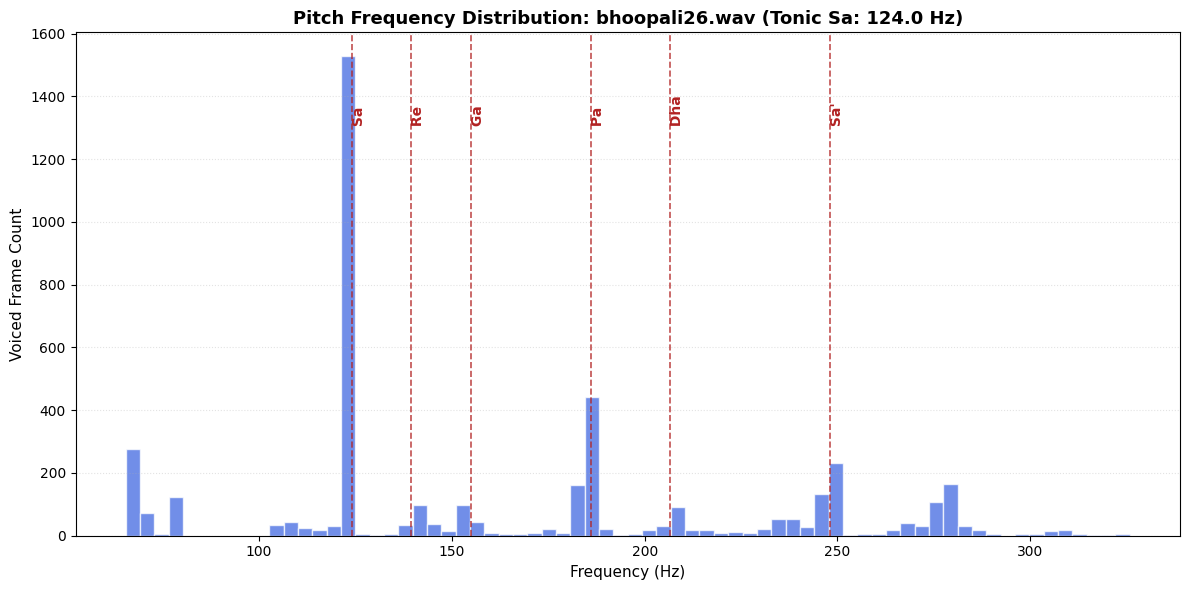

In [5]:
import librosa
import numpy as np
import scipy.stats
import matplotlib.pyplot as plt

# File configuration
audio_file = 'bhoopali26.wav'

# 1. Load audio and extract valid pitch frames
y, sr = librosa.load(audio_file, sr=22050)
f0, _, _ = librosa.pyin(y, fmin=librosa.note_to_hz('C2'), fmax=librosa.note_to_hz('C5'))
valid_f0 = f0[~np.isnan(f0)]

if len(valid_f0) == 0:
    raise ValueError(f"No clear pitch detected in {audio_file}")

# 2. Establish Performer's Tonic Sa
tonic_sa = float(scipy.stats.mode(np.round(valid_f0), keepdims=True).mode[0])

# 3. Plot Frequency Histogram
plt.figure(figsize=(12, 6))
counts, bins, patches = plt.hist(valid_f0, bins=70, color='royalblue', alpha=0.75, edgecolor='white')

# Overlay theoretical vertical swara lines for Raag Bhoopali
swara_ratios = {'Sa': 1.0, 'Re': 1.125, 'Ga': 1.25, 'Pa': 1.5, 'Dha': 1.666, "Sa'": 2.0}
for name, ratio in swara_ratios.items():
    freq = tonic_sa * ratio
    plt.axvline(x=freq, color='firebrick', linestyle='--', alpha=0.8, linewidth=1.2)
    plt.text(freq, np.max(counts) * 0.85, f" {name}", color='firebrick', fontweight='bold', rotation=90, fontsize=10)

plt.title(f"Pitch Frequency Distribution: {audio_file} (Tonic Sa: {tonic_sa:.1f} Hz)", fontsize=13, fontweight='bold')
plt.xlabel("Frequency (Hz)", fontsize=11)
plt.ylabel("Voiced Frame Count", fontsize=11)
plt.grid(axis='y', linestyle=':', alpha=0.35)
plt.tight_layout()
plt.show()

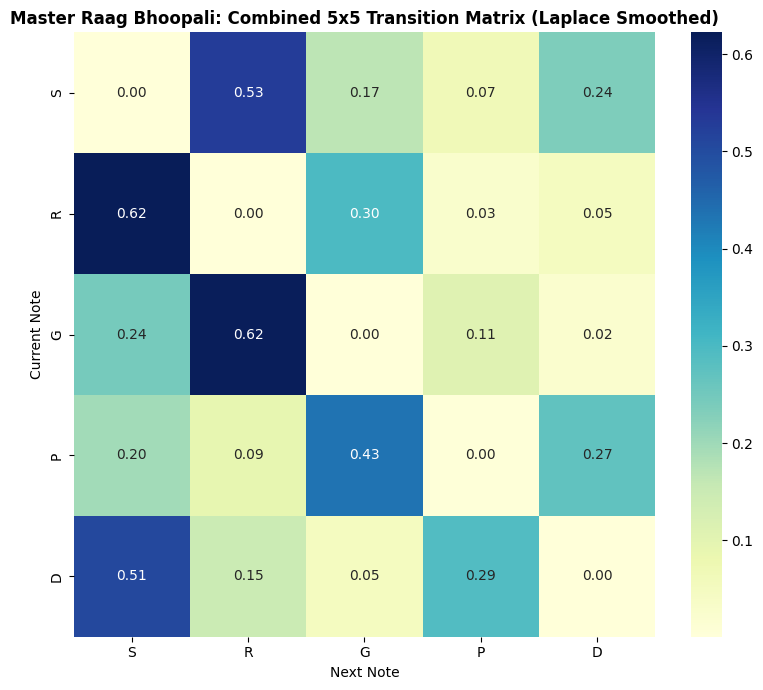

Total processed files: 15
Sequence lengths: [129, 132, 132, 180, 157, 68, 176, 189, 190, 274, 258, 230, 282, 442, 383]


In [6]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Restrict vocabulary strictly to Bhoopali's 5 pentatonic swaras
bhoopali_vocab_5 = ['S', 'R', 'G', 'P', 'D']
master_counts = pd.DataFrame(0, index=bhoopali_vocab_5, columns=bhoopali_vocab_5)

# Collect and process all 15 audio files
all_sequences = []
for i in range(26, 41):
    filename = f'bhoopali{i}.wav'
    if i == 28 and not os.path.exists(filename):
        filename = 'bhoopali28.mp3'

    if os.path.exists(filename):
        seq = get_swara_sequence(filename)
        all_sequences.append(seq)
    else:
        print(f"File not found: {filename}")

# Aggregate state transitions across all captured sequences
for seq in all_sequences:
    for i in range(len(seq) - 1):
        curr_note = seq[i]
        next_note = seq[i + 1]
        if curr_note in master_counts.index and next_note in master_counts.columns:
            master_counts.loc[curr_note, next_note] += 1

# Apply Laplace smoothing (+1) across only the 5 valid states
smoothed_counts = master_counts + 1
combined_transition_matrix = smoothed_counts.div(smoothed_counts.sum(axis=1), axis=0)

# Visualize the 5x5 master transition heatmap
plt.figure(figsize=(8, 7))
sns.heatmap(
    combined_transition_matrix,
    annot=True,
    cmap="YlGnBu",
    fmt=".2f",
    xticklabels=bhoopali_vocab_5,
    yticklabels=bhoopali_vocab_5
)
plt.title("Master Raag Bhoopali: Combined 5x5 Transition Matrix (Laplace Smoothed)", fontsize=12, fontweight='bold')
plt.xlabel("Next Note", fontsize=10)
plt.ylabel("Current Note", fontsize=10)
plt.tight_layout()
plt.show()

print(f"Total processed files: {len(all_sequences)}")
print("Sequence lengths:", [len(s) for s in all_sequences])

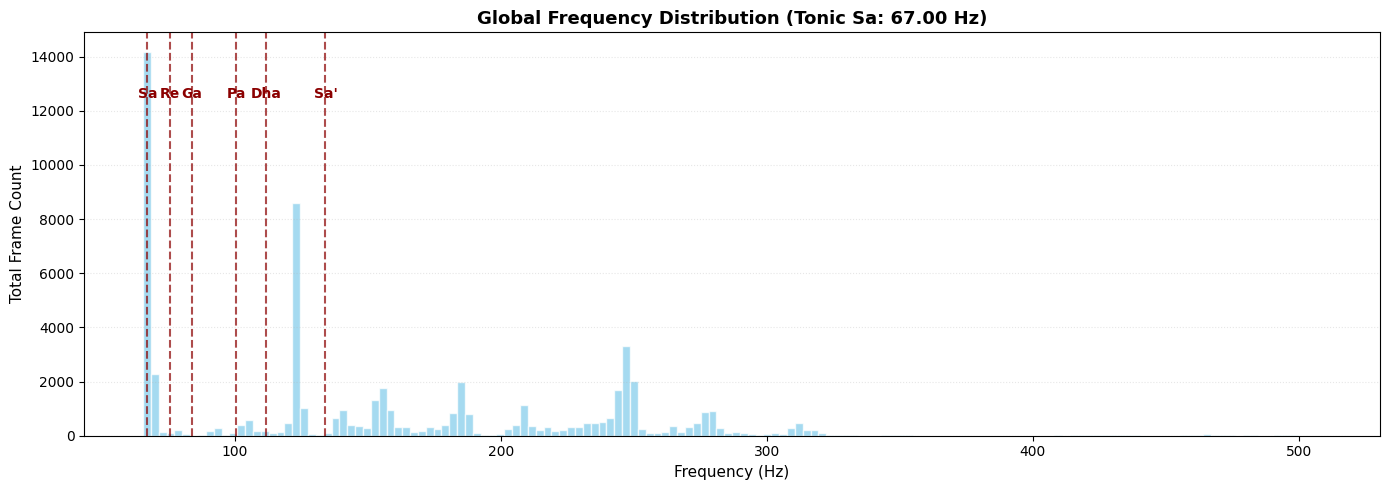

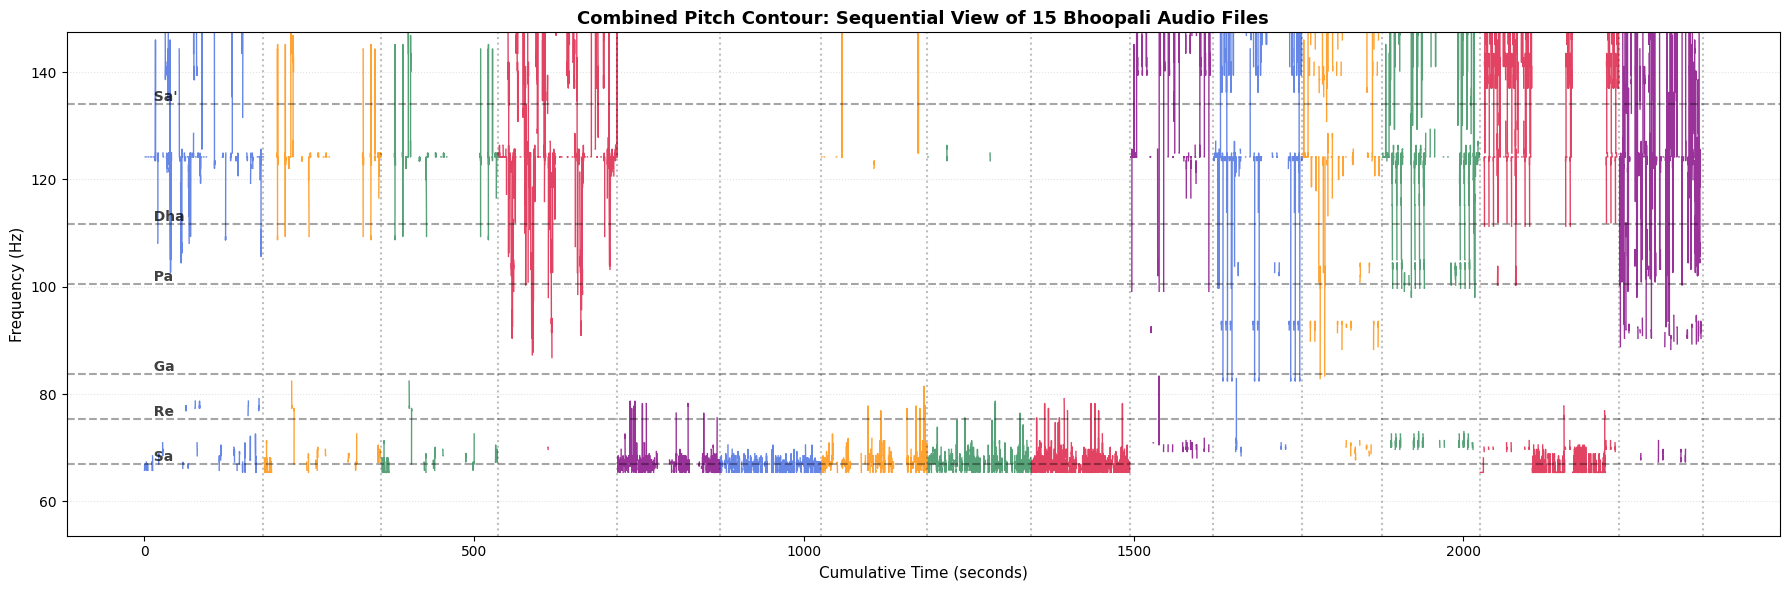

In [7]:
import os
import librosa
import numpy as np
import scipy.stats
import matplotlib.pyplot as plt

# Aggregate all f0 tracks and timestamps
all_f0_lists = []
all_times_lists = []

for i in range(26, 41):
    filename = f'bhoopali{i}.wav'
    if i == 28 and not os.path.exists(filename):
        filename = 'bhoopali28.mp3'

    if os.path.exists(filename):
        y, sr = librosa.load(filename, sr=22050)
        # C2 (~65 Hz) avoids capturing low-frequency rumble/sub-bass noise
        f0, _, _ = librosa.pyin(y, fmin=librosa.note_to_hz('C2'), fmax=librosa.note_to_hz('C5'))
        times = librosa.times_like(f0)
        all_f0_lists.append(f0)
        all_times_lists.append(times)

all_valid_f0 = np.concatenate([f[~np.isnan(f)] for f in all_f0_lists])
global_tonic = float(scipy.stats.mode(np.round(all_valid_f0), keepdims=True).mode[0])

# Strict Bhoopali Pentatonic Just-Intonation Ratios: Sa, Re, Ga, Pa, Dha, Sa'
bhoopali_ratios = {
    'Sa': 1.0,
    'Re': 9/8,        # ~1.125
    'Ga': 5/4,        # ~1.250
    'Pa': 3/2,        # ~1.500
    'Dha': 5/3,       # ~1.667
    "Sa'": 2.0
}

# --- Plot 1: Global Frequency Histogram ---
plt.figure(figsize=(14, 5))
counts, bins, patches = plt.hist(all_valid_f0, bins=150, color='skyblue', alpha=0.75, edgecolor='white')

for name, ratio in bhoopali_ratios.items():
    freq = global_tonic * ratio
    plt.axvline(x=freq, color='darkred', linestyle='--', alpha=0.7)
    # Fixed broken multiplication line: counts * 0.88
    plt.text(freq, np.max(counts) * 0.88, name, color='darkred', fontweight='bold', ha='center')

plt.title(f"Global Frequency Distribution (Tonic Sa: {global_tonic:.2f} Hz)", fontsize=13, fontweight='bold')
plt.xlabel("Frequency (Hz)", fontsize=11)
plt.ylabel("Total Frame Count", fontsize=11)
plt.grid(axis='y', linestyle=':', alpha=0.3)
plt.tight_layout()
plt.show()

# --- Plot 2: Chained Voice-Note Pitch Contours ---
plt.figure(figsize=(18, 6))
current_time_offset = 0
colors = ['royalblue', 'darkorange', 'seagreen', 'crimson', 'purple']

for i, (f0_single, times_single) in enumerate(zip(all_f0_lists, all_times_lists)):
    adjusted_times = times_single + current_time_offset
    plt.plot(adjusted_times, f0_single, color=colors[i % len(colors)], linewidth=1, alpha=0.8)
    plt.axvline(x=adjusted_times[-1], color='black', linestyle=':', alpha=0.25)
    current_time_offset = adjusted_times[-1] + 1

for name, ratio in bhoopali_ratios.items():
    freq = global_tonic * ratio
    plt.axhline(y=freq, color='black', linestyle='--', alpha=0.35)
    plt.text(0, freq, f"  {name}", color='black', alpha=0.75, va='bottom', fontsize=10, fontweight='bold')

plt.title(f"Combined Pitch Contour: Sequential View of {len(all_f0_lists)} Bhoopali Audio Files", fontsize=13, fontweight='bold')
plt.xlabel("Cumulative Time (seconds)", fontsize=11)
plt.ylabel("Frequency (Hz)", fontsize=11)
plt.ylim(global_tonic * 0.8, global_tonic * 2.2)
plt.grid(axis='y', linestyle=':', alpha=0.35)
plt.tight_layout()
plt.show()

In [8]:
swara_to_idx = {'S': 0, 'R': 1, 'G': 2, 'M': 3, 'P': 4, 'D': 5, 'N': 6}

X_list = []
for seq in all_sequences:
    numeric_seq = [swara_to_idx[s] for s in seq if s in swara_to_idx]
    if len(numeric_seq) > 0:
        X_list.append(np.array(numeric_seq).reshape(-1, 1))

X_combined = np.concatenate(X_list)
lengths = [len(x) for x in X_list]

# Initialize 7x7 Categorical HMM
model_bhoopali = hmm.CategoricalHMM(
    n_components=7,
    n_features=7,
    n_iter=500,
    tol=0.001,
    init_params="",
    params="st",        # Update start and transition matrices; lock emissions
    random_state=42
)

# Prior probabilities
model_bhoopali.startprob_ = np.full(7, 1/7)

# Seed transitions with base floor to eliminate absolute zeros
rng = np.random.default_rng(42)
raw_trans = rng.uniform(0.1, 0.9, (7, 7)) + 0.01
model_bhoopali.transmat_ = raw_trans / raw_trans.sum(axis=1, keepdims=True)

# Lock emissions directly to swara indices
model_bhoopali.emissionprob_ = np.eye(7)

print("Training Master 7x7 Bhoopali Model...")
model_bhoopali.fit(X_combined, lengths=lengths)

# Post-fit zero cleanup
model_bhoopali.transmat_ = np.where(model_bhoopali.transmat_ == 0, 1e-5, model_bhoopali.transmat_)
model_bhoopali.transmat_ /= model_bhoopali.transmat_.sum(axis=1, keepdims=True)

# Save master model
joblib.dump(model_bhoopali, 'bhoopali_combined.pkl')
print("Saved bhoopali_combined.pkl successfully.")

Training Master 7x7 Bhoopali Model...
Saved bhoopali_combined.pkl successfully.


In [9]:
def score_bhoopali_audio(file_path, trained_model):
    new_seq = get_swara_sequence(file_path)
    if not new_seq:
        return -np.inf, []

    numeric_seq = np.array([swara_to_idx[s] for s in new_seq if s in swara_to_idx]).reshape(-1, 1)
    if len(numeric_seq) == 0:
        return -np.inf, []

    raw_score = trained_model.score(numeric_seq)
    normalized_score = raw_score / len(numeric_seq)
    return normalized_score, new_seq

# --- Test run on a sample file ---
test_file = 'bhoopali30.wav'
if os.path.exists(test_file):
    score, seq = score_bhoopali_audio(test_file, model_bhoopali)
    print(f"File: {test_file}")
    print(f"Extracted Sequence: {seq}")
    print(f"Normalized Log-Likelihood: {score:.4f}")
    if score > -1.6:
        print("Verdict: Strong match for Raag Bhoopali!")
    else:
        print("Verdict: Low confidence / grammar mismatch.")

File: bhoopali30.wav
Extracted Sequence: ['S', 'R', 'S', 'R', 'S', 'G', 'S', 'R', 'S', 'R', 'G', 'R', 'S', 'R', 'S', 'R', 'S', 'R', 'G', 'S', 'R', 'S', 'D', 'P', 'D', 'S', 'G', 'S', 'R', 'S', 'R', 'S', 'G', 'S', 'D', 'R', 'S', 'R', 'S', 'R', 'S', 'D', 'S', 'R', 'S', 'D', 'P', 'D', 'P', 'D', 'P', 'D', 'P', 'D', 'S', 'R', 'S', 'R', 'S', 'D', 'R', 'S', 'R', 'G', 'R', 'G', 'R', 'S', 'R', 'S', 'D', 'S', 'D', 'P', 'S', 'R', 'S', 'R', 'S', 'R', 'S', 'G', 'R', 'S', 'R', 'G', 'R', 'G', 'R', 'S', 'D', 'G', 'S', 'D', 'P', 'S', 'D', 'S', 'R', 'S', 'D', 'P', 'D', 'S', 'R', 'S', 'G', 'S', 'D', 'R', 'S', 'D', 'G', 'S', 'R', 'S', 'G', 'R', 'S', 'R', 'G', 'R', 'G', 'R', 'S', 'R', 'S', 'D', 'S', 'D', 'S', 'R', 'S', 'R', 'S', 'D', 'R', 'S', 'R', 'G', 'R', 'S', 'D', 'G', 'S', 'R', 'S', 'D', 'S', 'R', 'S', 'R', 'S', 'R', 'S', 'R', 'S']
Normalized Log-Likelihood: -0.9383
Verdict: Strong match for Raag Bhoopali!
